# E230 · Semantic learnability before control

**Complete** · E230 finished  
Updated 2026-11-23T11:22:43+01:00 Stockholm

E230 tests new-regime learning at the first A → B transition of four E229 walks. Each initial MAE model and optimizer is reconstructed by replaying E229’s exact A prefix. The 96-update incoming MAE readout can reproduce E229’s first-clip reference. The main comparison uses four fresh independent augmentation draws per walk. The longer horizons extend the same two raw B videos using unique chronological frame positions. Independent semantic scores are five-task balanced-accuracy means for the incoming B and earlier A panels. Labels only enter evaluation.

Each trainable arm sees 96, 384 and 768 optimizer updates at batch size two. Each replay batch retains one incoming image and adds one earlier A image. Both SimSiam variants use two augmented views and inherit MAE encoder weights and AdamW moments. Their heads train for 192 steps on A with the encoder frozen, then start B at a 7.5e-5 encoder rate and a 3e-4 head rate. MAE uses 7.5e-5. The longer-adaptation MAE baseline is the same incoming trajectory read later. E228 found a positive replay effect below its +0.25 pp gate; replay remains a comparator here.

## Stage A · Can the representations learn B?

Mean frozen B score **63.21%**. The first-stage gate is +0.5 pp with a positive lower walk interval on a prespecified arm and duration.

| Updates | Strategy | New B versus frozen (pp) | Earlier A versus frozen (pp) | Family-adjusted B lower bound (pp) |
| --- | --- | --- | --- | --- |
| 96 | No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 |
| 96 | Incoming MAE | -0.147 [-0.692, +0.299] | +1.372 [+0.693, +2.170] | -0.709 |
| 96 | Historical replay MAE | +0.464 [-0.189, +1.128] | +0.696 [+0.198, +1.194] | -0.257 |
| 96 | Incoming SimSiam | -0.212 [-0.814, +0.439] | +0.664 [+0.196, +1.144] | -0.891 |
| 96 | Historical replay SimSiam | -0.724 [-1.345, -0.103] | +0.863 [+0.707, +0.979] | -1.346 |
| 384 | No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 |
| 384 | Incoming MAE | -0.540 [-0.937, -0.057] | +0.930 [-0.368, +2.229] | -0.967 |
| 384 | Historical replay MAE | +0.165 [-0.499, +0.829] | +0.815 [-0.018, +1.362] | -0.613 |
| 384 | Incoming SimSiam | -0.008 [-0.518, +0.502] | +0.691 [+0.398, +0.984] | -0.676 |
| 384 | Historical replay SimSiam | -0.583 [-1.329, +0.217] | +0.968 [+0.754, +1.191] | -1.364 |
| 768 | No adaptation | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 |
| 768 | Incoming MAE | -0.337 [-1.082, +0.279] | +1.934 [+0.996, +2.871] | -1.221 |
| 768 | Historical replay MAE | -0.846 [-1.629, +0.086] | +0.755 [+0.512, +1.055] | -1.684 |
| 768 | Incoming SimSiam | -0.691 [-1.336, +0.192] | +0.640 [+0.460, +0.842] | -1.363 |
| 768 | Historical replay SimSiam | -0.470 [-1.156, +0.240] | +1.130 [+0.855, +1.368] | -1.195 |

| Updates | Strategy | Actual steps | Incoming | Replay | SSL views | Training seconds | A head steps | A head seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 96 | No adaptation | 0 | 0 | 0 | 0 | 0.00 | 0 | 0.00 |
| 96 | Incoming MAE | 96 | 192 | 0 | 192 | 0.95 | 0 | 0.00 |
| 96 | Historical replay MAE | 96 | 96 | 96 | 192 | 0.95 | 0 | 0.00 |
| 96 | Incoming SimSiam | 96 | 192 | 0 | 384 | 1.86 | 192 | 2.40 |
| 96 | Historical replay SimSiam | 96 | 96 | 96 | 384 | 1.85 | 192 | 2.40 |
| 384 | No adaptation | 0 | 0 | 0 | 0 | 0.00 | 0 | 0.00 |
| 384 | Incoming MAE | 384 | 768 | 0 | 768 | 3.79 | 0 | 0.00 |
| 384 | Historical replay MAE | 384 | 384 | 384 | 768 | 3.79 | 0 | 0.00 |
| 384 | Incoming SimSiam | 384 | 768 | 0 | 1536 | 7.47 | 192 | 2.40 |
| 384 | Historical replay SimSiam | 384 | 384 | 384 | 1536 | 7.43 | 192 | 2.40 |
| 768 | No adaptation | 0 | 0 | 0 | 0 | 0.00 | 0 | 0.00 |
| 768 | Incoming MAE | 768 | 1536 | 0 | 1536 | 7.57 | 0 | 0.00 |
| 768 | Historical replay MAE | 768 | 768 | 768 | 1536 | 7.57 | 0 | 0.00 |
| 768 | Incoming SimSiam | 768 | 1536 | 0 | 3072 | 14.86 | 192 | 2.40 |
| 768 | Historical replay SimSiam | 768 | 768 | 768 | 3072 | 14.91 | 192 | 2.40 |

**Stage A gate stayed closed.** No strategy reached the acquisition criterion.

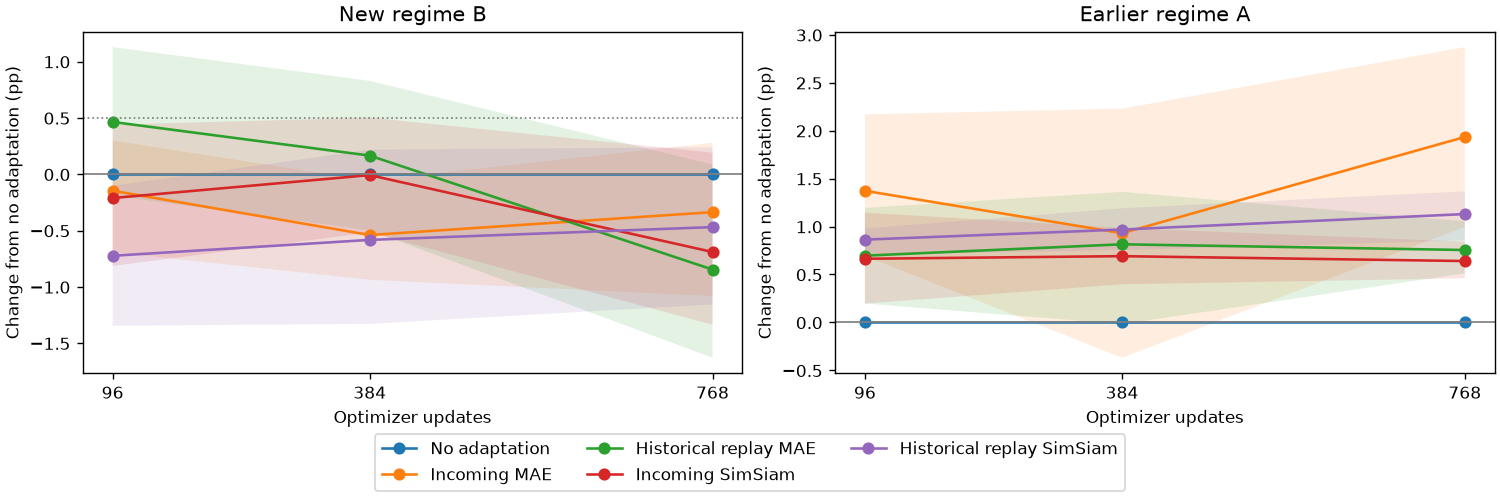

## Stage C · Gradient-interference pilot

32 audit states on 4 walks. Eight historical candidates per state use the negative encoder gradient dot product. Actual reconstruction damage uses an AdamW trial and matched historical masking. Historical semantic damage uses independent A probes.

| Readout | Spearman correlation and walk-clustered interval |
| --- | --- |
| Historical loss increase after one update | +0.237 [-0.064, +0.539] |
| Independent A semantic damage after one update | +0.060 [-0.460, +0.430] |
| Independent A semantic damage after 16 updates | -0.093 [-0.515, +0.309] |